In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import shap

c:\Users\kingd\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv('city_day.csv')
df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


# Data Preparation

In [3]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nData Types:")
df.info()

Shape: (29531, 16)

Columns:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

Data Types:
<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-nul

In [4]:
df.isnull().sum()

City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

In [5]:
df = df.drop(['City', 'Date', 'AQI_Bucket'], axis=1)
df = df.dropna()
df.isnull().sum()

PM2.5      0
PM10       0
NO         0
NO2        0
NOx        0
NH3        0
CO         0
SO2        0
O3         0
Benzene    0
Toluene    0
Xylene     0
AQI        0
dtype: int64

In [6]:
X = df.drop('AQI', axis=1)
y = df['AQI']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build Multiple ML Models / Hyperparameter Tuning 

In [7]:
models = {
    'Linear Regression': make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),

    'Polynomial Regression': make_pipeline(
        PolynomialFeatures(include_bias=False),
        StandardScaler(),
        LinearRegression()
    ),

    'Ridge': make_pipeline(
        StandardScaler(),
        Ridge()
    ),

    'Lasso': make_pipeline(
        StandardScaler(),
        Lasso(max_iter=10000)
    ),

    'Elastic Net': make_pipeline(
        StandardScaler(),
        ElasticNet(max_iter=10000)
    ),

    'KNN Regression': make_pipeline(
        StandardScaler(),
        KNeighborsRegressor()
    ),

    'Decision Tree Regression': DecisionTreeRegressor(
        random_state=42
    ),

    'SVR': make_pipeline(
        StandardScaler(),
        SVR(kernel='rbf')
    )
}

In [ ]:
param_grids = {

    'Linear Regression': {},

    'Polynomial Regression': {
        'polynomialfeatures__degree': [2, 3, 4]
    },

    'Ridge': {
        'ridge__alpha': [0.001, 0.01, 0.1, 1, 10, 100]
    },

    'Lasso': {
        'lasso__alpha': [0.0001, 0.001, 0.01, 0.1, 1],
        'lasso__max_iter': [10000]
    },

    'Elastic Net': {
        'elasticnet__alpha': [0.001, 0.01, 0.1, 1],
        'elasticnet__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9],
        'elasticnet__max_iter': [10000]
    },

    'KNN Regression': {
        'kneighborsregressor__n_neighbors': [3, 5, 7, 9, 11, 15],
        'kneighborsregressor__weights': ['uniform', 'distance'],
        'kneighborsregressor__p': [1, 2]
    },

    'Decision Tree Regression': {
        'max_depth': [3, 5, 7, 10, 15, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4]
    },

    'SVR': {
        'svr__C': [0.1, 1, 10, 100],
        'svr__epsilon': [0.01, 0.1, 0.2, 0.5],
        'svr__gamma': ['scale', 'auto', 0.01, 0.1, 1]
    }
}

In [9]:
from sklearn.model_selection import GridSearchCV

results = []
best_models = {}

for name, model in models.items():

    print(f"Tuning {name}...")

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        cv=5,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1,
        refit=True
    )

    grid_search.fit(X_train, y_train)

    best_models[name] = grid_search.best_estimator_

    results.append({
        'Model': name,
        'Best Parameters': grid_search.best_params_,
        'CV RMSE': -grid_search.best_score_
    })

    print("Best Parameters:", grid_search.best_params_)
    print("Best CV RMSE:", -grid_search.best_score_)
    print("-" * 50)

Tuning Linear Regression...
Best Parameters: {}
Best CV RMSE: 28.173623753531324
--------------------------------------------------
Tuning Polynomial Regression...
Best Parameters: {'polynomialfeatures__degree': 2}
Best CV RMSE: 26.268522693461314
--------------------------------------------------
Tuning Ridge...
Best Parameters: {'ridge__alpha': 10}
Best CV RMSE: 28.1716171922419
--------------------------------------------------
Tuning Lasso...
Best Parameters: {'lasso__alpha': 0.1, 'lasso__max_iter': 10000}
Best CV RMSE: 28.171040877078873
--------------------------------------------------
Tuning Elastic Net...
Best Parameters: {'elasticnet__alpha': 0.01, 'elasticnet__l1_ratio': 0.5, 'elasticnet__max_iter': 10000}
Best CV RMSE: 28.17083100945134
--------------------------------------------------
Tuning KNN Regression...
Best Parameters: {'kneighborsregressor__n_neighbors': 5, 'kneighborsregressor__p': 2, 'kneighborsregressor__weights': 'distance'}
Best CV RMSE: 25.954202455161045
--

In [10]:
best_models = {
    'Linear Regression': make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),

    'Polynomial Regression': make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(),
        LinearRegression()
    ),

    'Ridge': make_pipeline(
        StandardScaler(),
        Ridge(alpha=10)
    ),

    'Lasso': make_pipeline(
        StandardScaler(),
        Lasso(alpha=0.1, max_iter=10000)
    ),

    'Elastic Net': make_pipeline(
        StandardScaler(),
        ElasticNet(
            alpha=0.01,
            l1_ratio=0.5,
            max_iter=10000
        )
    ),

    'KNN Regression': make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(
            n_neighbors=5,
            weights='distance',
            p=2
        )
    ),

    'Decision Tree Regression': DecisionTreeRegressor(
        max_depth=7,
        min_samples_split=2,
        min_samples_leaf=4,
        random_state=42
    ),

    'SVR': make_pipeline(
        StandardScaler(),
        SVR(
            kernel='rbf',
            C=100,
            epsilon=0.01,
            gamma=0.01
        )
    )
}


# Model Evaluation

In [11]:
results = []

for name, model in best_models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append({
        'Model': name,
        'R2': r2_score(y_test, y_pred),
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred))
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='R2', ascending=False
)

print(results_df.to_string(index=False))

                   Model       R2       MAE      RMSE
                     SVR 0.935770 15.582903 23.117253
          KNN Regression 0.931153 16.144849 23.933667
   Polynomial Regression 0.929993 16.738860 24.134441
       Linear Regression 0.921714 18.153469 25.521692
                   Ridge 0.921645 18.161199 25.532868
                   Lasso 0.921601 18.169064 25.540033
             Elastic Net 0.921529 18.174527 25.551756
Decision Tree Regression 0.919166 17.650514 25.933744


# Feature Importance (Explainable ML)

In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
svr_model = SVR(
    kernel='rbf',
    C=100,
    epsilon=0.01,
    gamma=0.01
)
svr_model.fit(X_train_scaled, y_train)

,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.01
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",100
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.01
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [14]:
background = shap.sample(
    X_train_scaled,
    30,
    random_state=42
)

explainer = shap.KernelExplainer(
    svr_model.predict,
    background
)

X_test_sample = shap.sample(
    X_test_scaled,
    100,
    random_state=42
)

shap_values = explainer.shap_values(
    X_test_sample,
    nsamples=100
)

  0%|          | 0/100 [00:00<?, ?it/s]

100%|██████████| 100/100 [01:45<00:00,  1.06s/it]


In [18]:
shap_exp = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        shap_values.shape[0],
        float(np.array(explainer.expected_value).squeeze())
    ),
    data=X_test_sample,
    feature_names=X_train.columns.tolist()
)

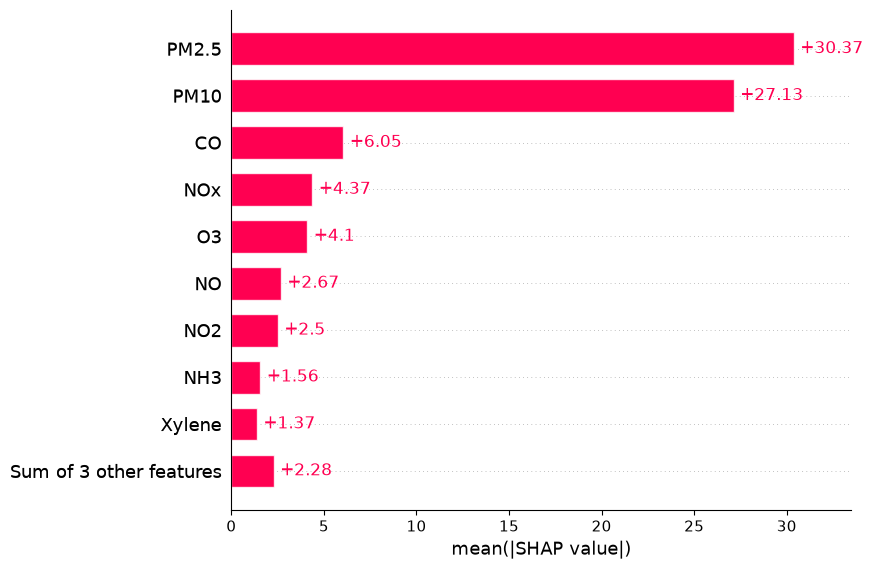

In [19]:
shap.plots.bar(shap_exp)

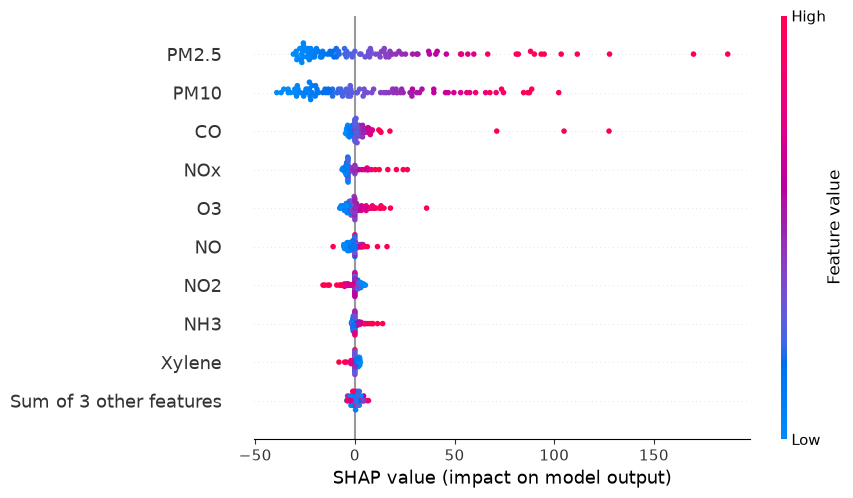

In [20]:
shap.plots.beeswarm(shap_exp)

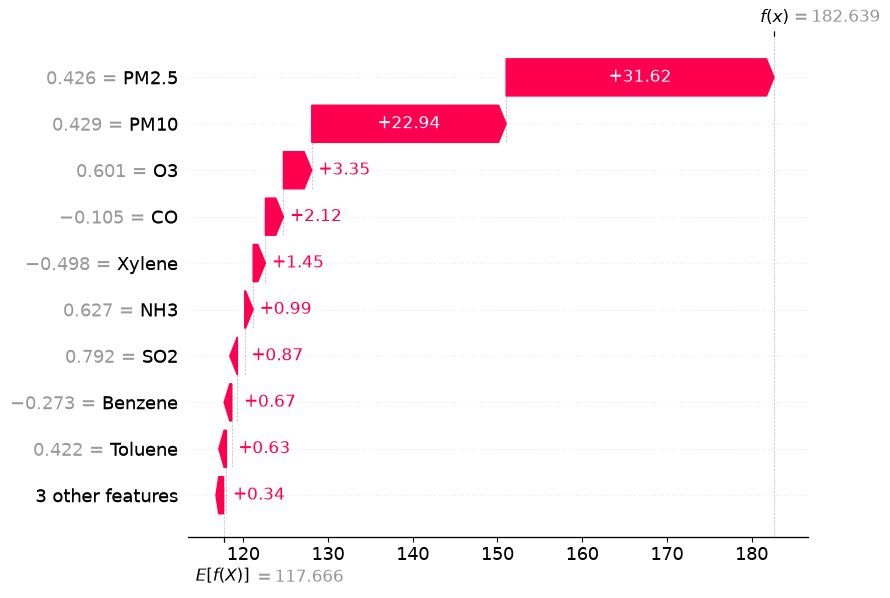

In [21]:
i = 0
shap.plots.waterfall(shap_exp[i])

# Environmental Interpretation 
จากการวิเคราะห์ความสำคัญของตัวแปรด้วย SHAP พบว่า PM2.5 และ PM10 เป็นตัวแปรที่มีอิทธิพลต่อการพยากรณ์ค่าดัชนีคุณภาพอากาศ(AQI) มากที่สุด ซึ่งสูงกว่าตัวแปรอื่นอย่างชัดเจน

SHAP analysis revealed that PM2.5 and PM10 were the most influential features in predicting the Air Quality Index (AQI), with substantially greater contributions than the other variables.